# Final P1 Demo Walkthrough (Sprint 10 / D50)

One consistent real example - `gcp_microservices_demo` (Online Boutique) -
taken end to end through every P1 stage built across Sprints 1-9: load,
preprocess, detect, segment, extract geometric relations, embed + OCR a
component, align to real code, and compute impact/recommendation for a
controlled violation. Every number shown here is computed live in this
notebook, not pasted in.

In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent
BACKEND_DIR = REPO_ROOT / "backend"
sys.path.insert(0, str(BACKEND_DIR))

from app.modules.cv_pipeline.dataset_manifest import DIAGRAMS_DIR, load_manifest
from app.modules.cv_pipeline.pipeline import CVPreprocessor, ComponentDetector
from app.modules.cv_pipeline.segmentation import RegionProposalSegmenter
from app.modules.cv_pipeline.geometry_relations import detect_lines, propose_relations
from app.modules.cv_pipeline.embeddings import ComponentEmbedder
from app.modules.cv_pipeline.ocr import RegionOCR
from app.modules.cv_pipeline.name_matching import best_match
from app.modules.cv_pipeline.impact_analysis import build_networkx_graph, compute_affected_nodes
from app.modules.cv_pipeline.recommendations import generate_recommendation
from app.schemas.models import ArchViolation

g = next(x for x in load_manifest() if x.id == "gcp_microservices_demo")
img_path = DIAGRAMS_DIR / Path(g.source).name
print(f"Diagram: {g.name}")
print(f"Real repository: {g.metadata['source_repository']['repo_url']}")
print(f"{len(g.components)} ground-truth components, {len(g.relationships)} ground-truth relationships")

Diagram: Online Boutique (GoogleCloudPlatform/microservices-demo)
Real repository: https://github.com/GoogleCloudPlatform/microservices-demo
12 ground-truth components, 16 ground-truth relationships


## 1. Load and preprocess

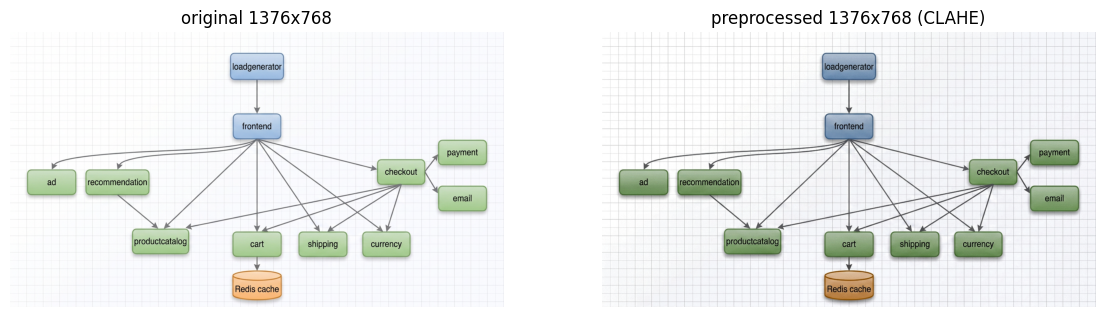

In [2]:
import matplotlib.pyplot as plt

preprocessor = CVPreprocessor()
original = preprocessor.load(str(img_path))
processed = preprocessor.preprocess(str(img_path), color_mode="rgb")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(preprocessor.to_rgb(original)); axes[0].set_title(f"original {original.shape[1]}x{original.shape[0]}"); axes[0].axis("off")
axes[1].imshow(processed); axes[1].set_title(f"preprocessed {processed.shape[1]}x{processed.shape[0]} (CLAHE)"); axes[1].axis("off")
plt.show()

## 2. Component detection (pretrained YOLOv8n) and segmentation (region-cropping)

In [3]:
model_path = BACKEND_DIR / "models" / "yolov8n.pt"
detector = ComponentDetector(model_path=str(model_path) if model_path.exists() else None, confidence=0.25)
detections = detector.detect(preprocessor.preprocess(str(img_path)))
print(f"YOLOv8n/COCO detections: {len(detections)} (expected near-zero - see docs/sprint3_detection_baseline.md)")

segmenter = RegionProposalSegmenter()
regions = segmenter.propose_regions(preprocessor.preprocess(str(img_path)))
print(f"Region-cropping proposals: {len(regions)} (vs {len(g.components)} real components - over-segments, see docs/sprint4_segmentation_baseline.md)")

0: 384x640 (no detections), 876.5ms


Speed: 278.5ms preprocess, 876.5ms inference, 52.4ms postprocess per image at shape (1, 3, 384, 640)


YOLOv8n/COCO detections: 0 (expected near-zero - see docs/sprint3_detection_baseline.md)


Region-cropping proposals: 69 (vs 12 real components - over-segments, see docs/sprint4_segmentation_baseline.md)


## 3. Geometry-based relation extraction (the project's strongest CV baseline)

In [4]:
lines = detect_lines(original)
candidates = propose_relations(lines, g.components)
gt_pairs = {frozenset((r.source, r.target)) for r in g.relationships}
candidate_pairs = {frozenset((c.source, c.target)) for c in candidates}
tp = len(gt_pairs & candidate_pairs)
print(f"{len(lines)} lines detected -> {len(candidates)} relation candidates")
print(f"Matches {tp}/{len(gt_pairs)} real ground-truth relationships (precision/recall computed in docs/sprint5_vit_geometry_report.md)")

661 lines detected -> 13 relation candidates
Matches 11/16 real ground-truth relationships (precision/recall computed in docs/sprint5_vit_geometry_report.md)


## 4. Embedding (CLIP) + OCR on one real component crop

In [5]:
cart = next(c for c in g.components if c.id == "cart")
crop = original[int(cart.bbox.y1):int(cart.bbox.y2), int(cart.bbox.x1):int(cart.bbox.x2)]

embedder = ComponentEmbedder()
embedding = embedder.embed_region(crop)
print(f"CLIP embedding for '{cart.name}': {len(embedding)}-dim vector, first 5 values: {[round(v, 3) for v in embedding[:5]]}")

ocr = RegionOCR()
best_text = ocr.read_best_text(crop)
print(f"OCR on '{cart.name}' crop: {best_text.text!r} (confidence {best_text.confidence:.2f})" if best_text else "OCR found no text")

CLIP embedding for 'cart': 512-dim vector, first 5 values: [-0.037, 0.004, 0.047, -0.022, 0.056]


OCR on 'cart' crop: 'cart' (confidence 0.91)


## 5. Graph alignment: diagram component -> real code module

In [6]:
real_code_identifiers = [
    "adservice", "cartservice", "checkoutservice", "currencyservice", "emailservice",
    "frontend", "loadgenerator", "paymentservice", "productcatalogservice",
    "recommendationservice", "shippingservice", "shoppingassistantservice",
]
match = best_match(cart.name, real_code_identifiers, component_type=cart.type.value)
print(f"'{cart.name}' aligns to real code module: {match.code_identifier!r} (score {match.score:.2f})")

'cart' aligns to real code module: 'cartservice' (score 0.60)


## 6. Impact analysis + recommendation for a controlled violation

`recommendation -> cart` is a controlled (inserted) test violation from Sprint 8 - this edge does not exist in the real diagram.

In [7]:
nx_graph = build_networkx_graph(g)
impact = compute_affected_nodes(nx_graph, "recommendation", "cart")
print(f"Controlled violation recommendation -> cart affects:")
print(f"  upstream (depends on recommendation): {impact.upstream_affected}")
print(f"  downstream (recommendation now coupled to): {impact.downstream_affected}")

violation = ArchViolation(
    id="demo-v1", verdict="VIOLATION", violation_type="unexpected_dependency",
    source_component="recommendation", target_component="cart",
    expected="no direct recommendation -> cart dependency",
    actual="recommendation -> cart (inserted, controlled test violation)",
    severity="low", description="Controlled test violation for Sprint 8/10 demo purposes.",
)
print(f"\nRecommendation: {generate_recommendation(violation)}")

Controlled violation recommendation -> cart affects:
  upstream (depends on recommendation): ['frontend', 'loadgenerator']
  downstream (recommendation now coupled to): ['rediscache']

Recommendation: recommendation -> cart exists in the code but isn't documented in the intended architecture (actual: recommendation -> cart (inserted, controlled test violation)). Either update the diagram to reflect this real dependency, or remove it from the code if unintended.


## Summary

This single real example exercised every P1 module built across Sprints
1-9: dataset/schema (1), preprocessing (2), detection (3), segmentation
(4), embeddings/OCR/geometry (5), alignment (6), evidence plumbing (7, not
shown here - see `backend/scripts/demo_violation_evidence_chain.py` for the
real Git-evidence version against `flask_microservice_demo`), impact
analysis and recommendations (8). Full quantitative results across the
whole dataset are in `docs/cv_method_results_report.md`; limitations in
`docs/sprint10_limitations_and_verification.md`.